# Kelmarsh: the case study repeated on the six turbines

Protocol fixed before the run: [`README.md`](README.md), section "All turbines: protocol". Computation:
[`kelmarsh_all_turbines.py`](kelmarsh_all_turbines.py) (about ten minutes; run it to recompute the `results/all_*`
files, which this notebook reads). Data: Plumley & Takeuchi, *Kelmarsh wind farm data*, Zenodo 16807551,
CC-BY-4.0 (`plumley2025kelmarsh`). Method: `qlpca` (`lavado2011ijam`, `lavado2012phd`).
Numbers are reported without interpretation.

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RES = Path("results")
if not (RES / "all_summary.json").is_file():
    subprocess.run([sys.executable, "kelmarsh_all_turbines.py"], check=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
summary = json.load(open(RES / "all_summary.json", encoding="utf8"))
inc = pd.read_csv(RES / "all_inclusion.csv")
inc

,turbine,records_2019,records_2018,warning_active_2019,boundaries_estimated,excluded,reason
0,Kelmarsh_1,45567,45331,8677,True,False,NaN
1,Kelmarsh_2,47921,45990,66,True,False,NaN
2,Kelmarsh_3,46953,44921,13,True,False,NaN
3,Kelmarsh_4,47678,45760,2124,True,False,NaN
4,Kelmarsh_5,47320,45446,50,True,False,NaN
5,Kelmarsh_6,45853,44044,17,True,False,NaN


## Boundaries B1 – B4 per turbine (2018)

In [2]:
b = pd.read_csv(RES / "all_boundaries.csv").set_index("turbine")
b[[c for c in b.columns if "wind" in c] + [c for c in b.columns if "threshold" in c]]

,B1 wind (m/s),B2 wind (m/s),B3 wind (m/s),B4 wind (m/s),B1 threshold,B2 threshold,B3 threshold,B4 threshold
turbine,,,,,,,,
Kelmarsh_1,4.3514,8.6249,9.5533,10.7713,8.4915,14.8135,0.7130,1949.0434
Kelmarsh_2,4.3347,8.5282,9.5451,10.5721,8.4897,14.8155,0.7709,1945.3669
Kelmarsh_3,4.6202,8.7038,9.4743,10.6317,9.3029,14.8741,0.7175,1949.1767
Kelmarsh_4,4.3893,8.6295,9.5898,10.7265,8.4910,14.8121,0.7145,1946.4119
Kelmarsh_5,4.3221,8.5754,9.4071,10.6681,8.4917,14.8163,0.6271,1943.8668
Kelmarsh_6,4.5129,8.7390,9.3743,10.8111,9.3032,14.8541,0.6152,1941.1223


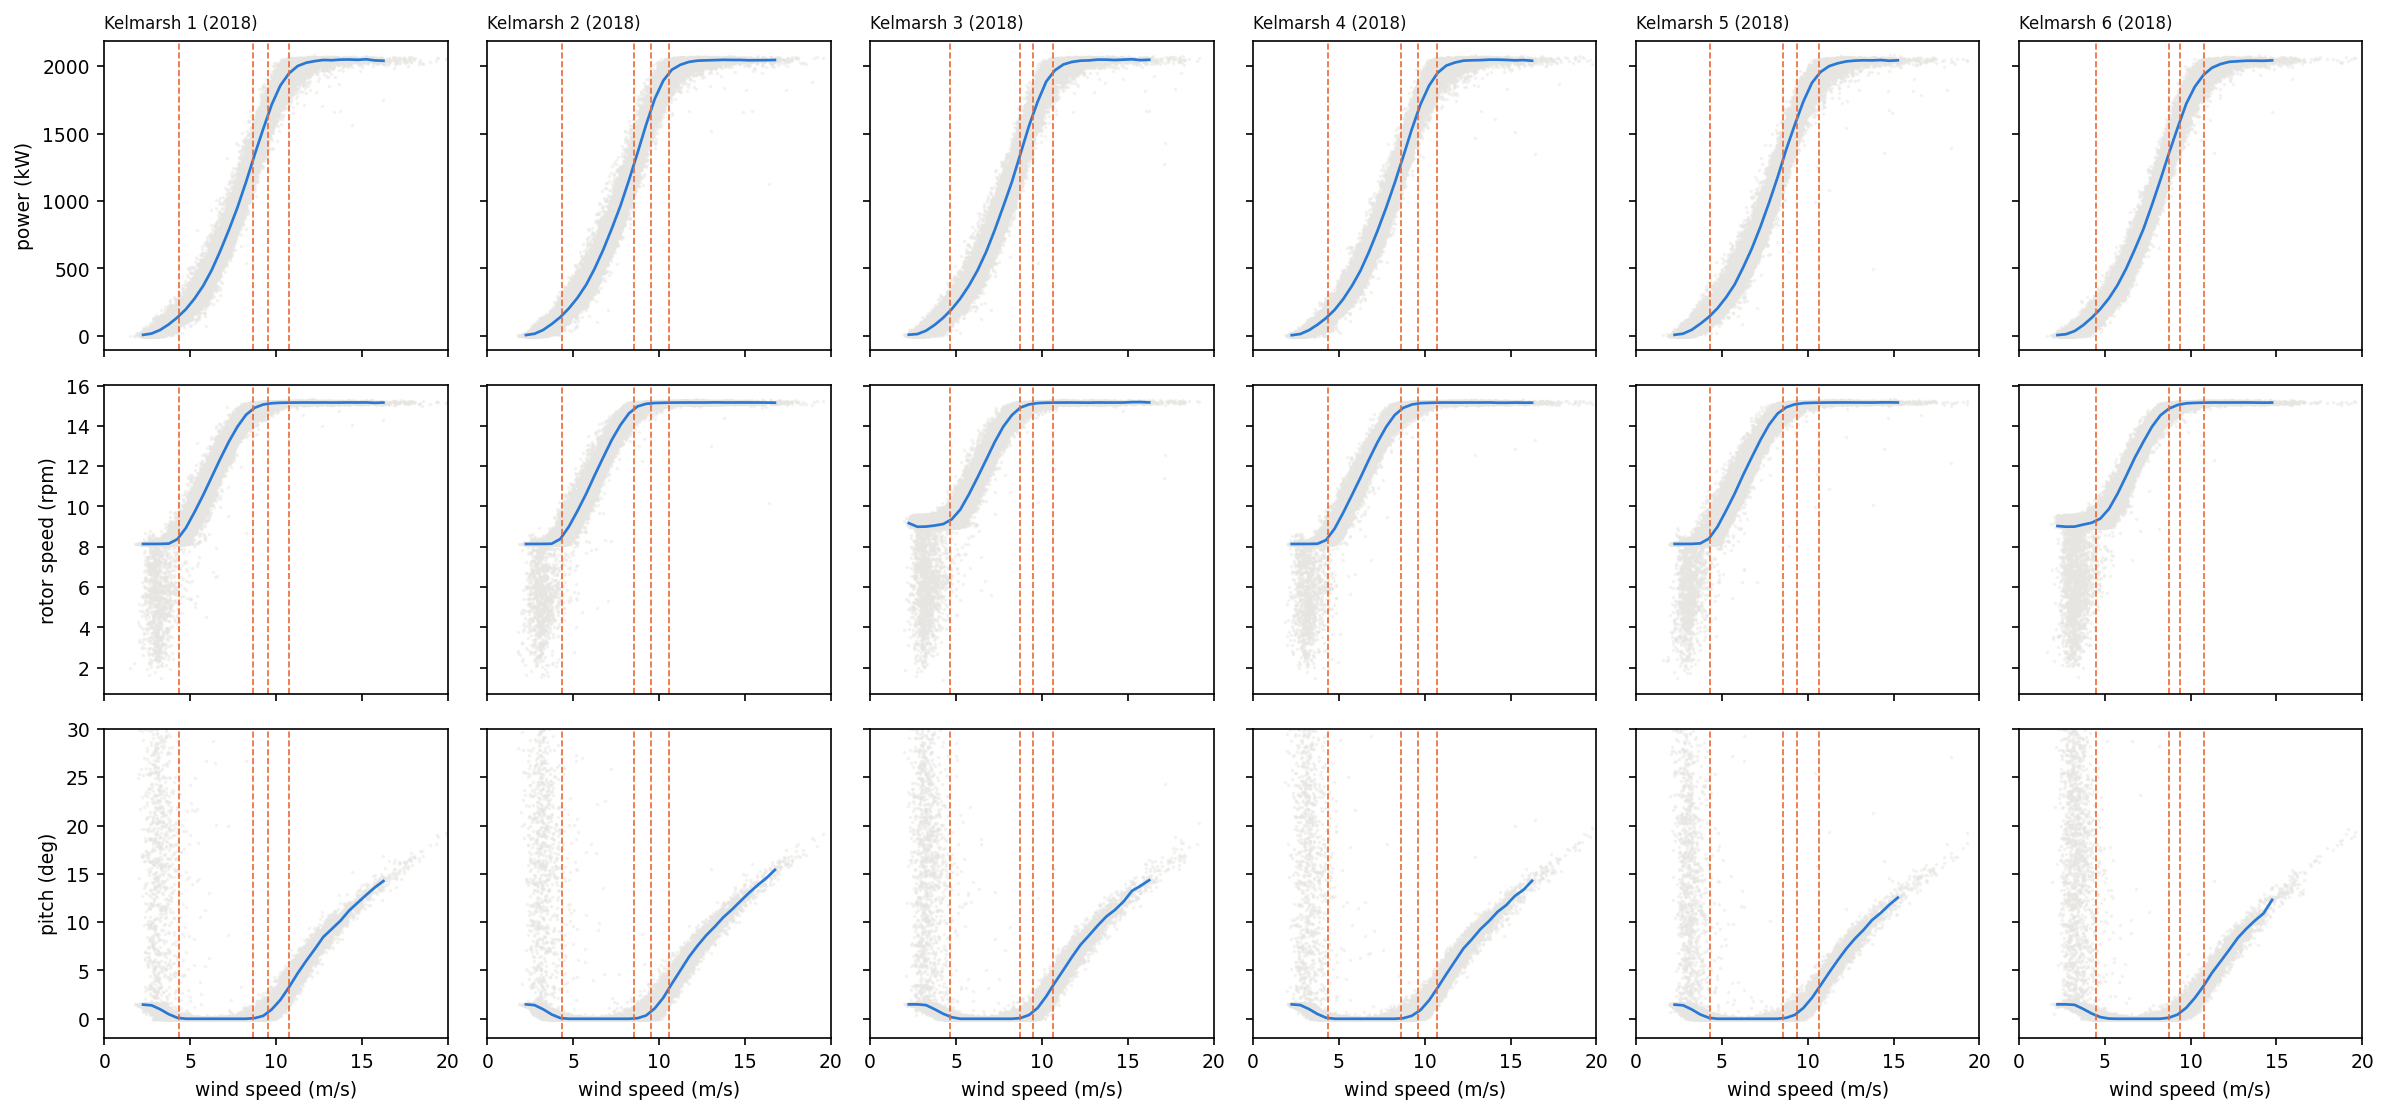

In [3]:
display(Image(RES / "all_operating_curves_2018.png"))

## VAF and gains over PCA (p = 2)

In [4]:
vaf = pd.read_csv(RES / "all_vaf.csv")
vaf.pivot(index="model", columns="turbine", values="paired gain").reindex(vaf.model.unique()).round(2)

turbine,Kelmarsh_1,Kelmarsh_2,Kelmarsh_3,Kelmarsh_4,Kelmarsh_5,Kelmarsh_6
model,,,,,,
PCA,NaN,NaN,NaN,NaN,NaN,NaN
percentile knots,8.53,11.93,8.04,11.45,10.60,7.88
"percentiles, same number of knots",8.98,12.77,8.68,12.22,11.21,8.36
"percentiles, same number of knots, monotone",6.87,9.97,6.87,8.93,7.25,5.85
control regions (2018),10.97,13.30,11.48,13.09,12.36,11.78
"control regions (2018), monotone",10.02,12.06,10.23,11.40,11.04,10.27


In [5]:
vaf.set_index(["turbine", "model"]).round(2)

parameters  VAF in sample  VAF out of sample    se  paired gain  se (gain)
turbine    model                                                                                                                  
Kelmarsh_1 PCA                                                   8          72.57              71.95  4.01          NaN        NaN
           percentile knots                                     23          80.63              80.48  2.10         8.53       1.97
           percentiles, same number of knots                    27          81.02              80.93  2.03         8.98       2.06
           percentiles, same number of knots, monotone          27          79.20              78.82  3.08         6.87       1.10
           control regions (2018)                               28          83.45              82.91  2.16        10.97       2.15
           control regions (2018), monotone                     28          82.64              81.97  2.55        10.02       1.80
Kelmarsh_2 PCA                                                   8          70.06              69.42  4.15          NaN        NaN
           percentile knots                                     23          81.54              81.35  2.30        11.93       1.92
           percentiles, same number of knots                    27          82.32              82.19  2.29        12.77       1.90
           percentiles, same number of knots, monotone          27          79.89              79.39  3.56         9.97       0.73
           control regions (2018)                               28          83.11              82.73  2.52        13.30       1.84
           control regions (2018), monotone                     28          81.96              81.48  3.11        12.06       1.44
Kelmarsh_3 PCA                                                   8          70.37              69.55  3.94          NaN        NaN
           percentile knots                                     23          78.23              77.59  2.06         8.04       2.35
           percentiles, same number of knots                    27          78.69              78.23  1.99         8.68       2.33
           percentiles, same number of knots, monotone          27          77.04              76.42  2.99         6.87       1.66
           control regions (2018)                               28          81.80              81.03  2.53        11.48       2.76
           control regions (2018), monotone                     28          80.65              79.79  3.04        10.23       2.49
Kelmarsh_4 PCA                                                   8          69.90              69.14  4.49          NaN        NaN
           percentile knots                                     23          80.95              80.59  2.36        11.45       2.30
           percentiles, same number of knots                    27          81.64              81.36  2.34        12.22       2.31
           percentiles, same number of knots, monotone          27          78.76              78.07  3.72         8.93       0.81
           control regions (2018)                               28          82.82              82.23  2.64        13.09       2.09
           control regions (2018), monotone                     28          81.38              80.54  3.40        11.40       1.61
Kelmarsh_5 PCA                                                   8          69.08              68.85  3.20          NaN        NaN
           percentile knots                                     23          79.41              79.45  1.44        10.60       2.42
           percentiles, same number of knots                    27          79.94              80.06  1.38        11.21       2.45
           percentiles, same number of knots, monotone          27          76.40              76.10  3.12         7.25       1.14
           control regions (2018)                               28          81.74              81.21  2.64        12.36       

## Main results: control regions minus percentiles with the same number of knots

(a) per turbine, paired over the 5 blocks; (b) number of turbines with a positive difference; (c) mean over the
turbines and its standard error between turbines. Sensitivity: without the `warning_active` records.

In [6]:
d = pd.read_csv(RES / "all_differences.csv")
display(d.pivot_table(index="turbine", columns=["data", "version"], values=["difference", "se"]).round(2))
pd.DataFrame({k: v for k, v in summary.items() if isinstance(v, dict) and "positive" in v}).T

difference                                                           se                                                 
data       all records              without warning_active              all records              without warning_active             
version       monotone unrestricted               monotone unrestricted    monotone unrestricted               monotone unrestricted
turbine                                                                                                                             
Kelmarsh_1        3.15         1.98                   3.03         2.03        0.72         0.43                   0.81         0.51
Kelmarsh_2        2.09         0.54                   2.08         0.53        0.80         0.70                   0.81         0.71
Kelmarsh_3        3.36         2.80                   3.34         2.79        0.85         0.94                   0.83         0.95
Kelmarsh_4        2.48         0.87                   2.43         0.78        0.93         1.07                   0.98         0.75
Kelmarsh_5        3.79         1.15                   3.70         1.04        0.52         1.51                   0.53         1.59
Kelmarsh_6        4.42         3.42                   4.43         3.43        1.38         1.37                   1.38         1.36

,positive,turbines,mean,se_between_turbines
"monotone, all records",6.0,6.0,3.2149,0.3472
"monotone, without warning_active",6.0,6.0,3.1679,0.3487
"unrestricted, all records",6.0,6.0,1.7922,0.4673
"unrestricted, without warning_active",6.0,6.0,1.7676,0.4807


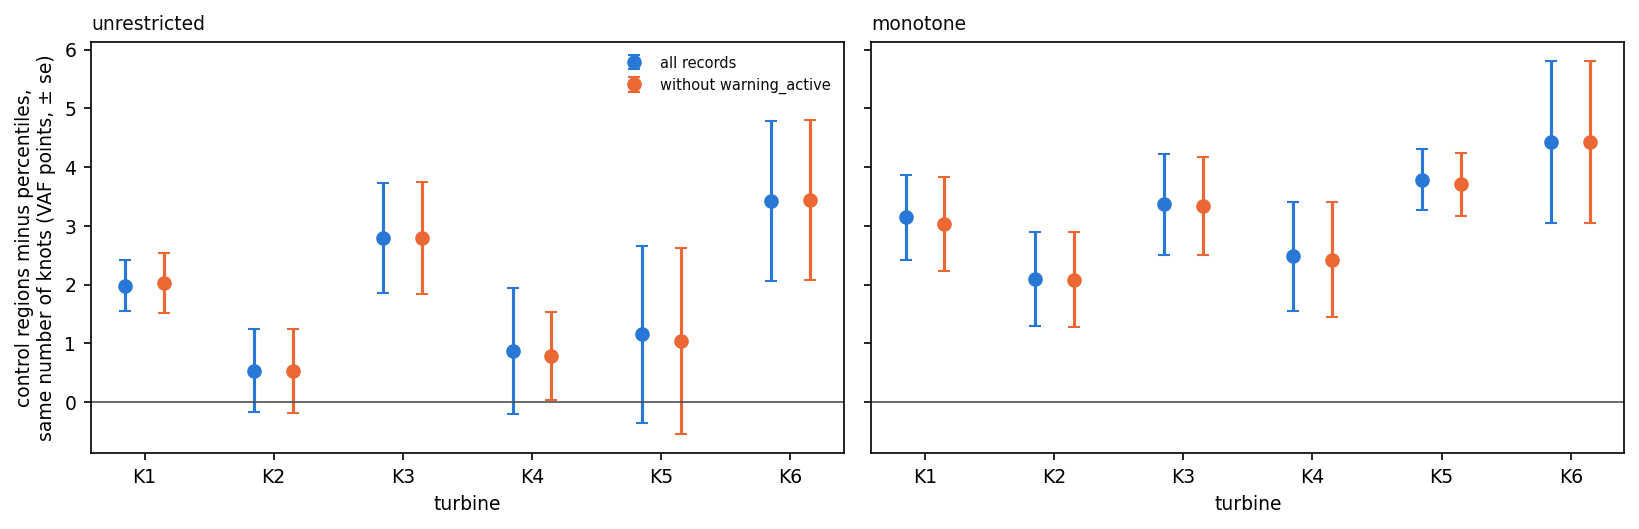

In [7]:
display(Image(RES / "all_differences.png"))

## Other facts per turbine

In [8]:
f = pd.read_csv(RES / "all_turbine_facts.csv").set_index("turbine")
f

,corr_rotor_generator,warning_active_in_sample,records_below_B1,startup_idle_below_B1,interior_knots_control,wind_speed_slope_below_B1,wind_speed_lowest_segment_slope_below_B1,wind_speed_lowest_segment_n_slope_below_B1,power_slope_below_B1,power_lowest_segment_slope_below_B1,power_lowest_segment_n_slope_below_B1,rotor_speed_slope_below_B1,rotor_speed_lowest_segment_slope_below_B1,rotor_speed_lowest_segment_n_slope_below_B1,control_gain_without_idle,control_gain_without_idle_se
turbine,,,,,,,,,,,,,,,,
Kelmarsh_1,1.0000,365,348,26,"{'wind_speed': 4, 'power': 4, 'rotor_speed': 2...",-1,"[2.123, 4.351]",348,-1,"[1.236, 149.085]",356,-1,"[2.088, 8.492]",357,7.8814,0.7538
Kelmarsh_2,1.0000,1,376,35,"{'wind_speed': 4, 'power': 4, 'rotor_speed': 2...",-1,"[1.974, 4.335]",376,-1,"[0.202, 149.524]",370,-1,"[2.466, 8.490]",372,9.9754,1.6699
Kelmarsh_3,1.0000,1,480,34,"{'wind_speed': 4, 'power': 4, 'rotor_speed': 2...",-1,"[2.314, 4.620]",480,-1,"[0.755, 181.300]",468,-1,"[2.428, 9.303]",379,8.3564,2.6486
Kelmarsh_4,0.9999,81,361,42,"{'wind_speed': 4, 'power': 4, 'rotor_speed': 2...",-1,"[1.971, 4.389]",361,-1,"[0.068, 148.700]",368,-1,"[1.945, 8.491]",378,9.2958,1.6190
Kelmarsh_5,1.0000,3,451,35,"{'wind_speed': 4, 'power': 4, 'rotor_speed': 2...",-1,"[1.537, 4.322]",451,-1,"[0.445, 149.453]",439,-1,"[2.793, 8.492]",444,8.8127,1.2627
Kelmarsh_6,1.0000,1,548,49,"{'wind_speed': 4, 'power': 4, 'rotor_speed': 2...",-1,"[2.177, 4.513]",548,-1,"[0.148, 168.976]",528,-1,"[2.363, 9.303]",420,8.0563,2.1063


In [9]:
print("Kelmarsh 1 reproduction check (case study):", summary["kelmarsh_1_check"])
print("excluded turbines:", summary["excluded"] or "none")
for k, v in summary.items():
    if isinstance(v, dict) and "positive" in v:
        print(f"{k}: positive in {v['positive']} of {v['turbines']}; mean {v['mean']:.2f} (se between turbines "
              f"{v['se_between_turbines']:.2f})")

Kelmarsh 1 reproduction check (case study): {'control_gain': 10.97, 'difference': 1.98}
excluded turbines: none
monotone, all records: positive in 6 of 6; mean 3.21 (se between turbines 0.35)
monotone, without warning_active: positive in 6 of 6; mean 3.17 (se between turbines 0.35)
unrestricted, all records: positive in 6 of 6; mean 1.79 (se between turbines 0.47)
unrestricted, without warning_active: positive in 6 of 6; mean 1.77 (se between turbines 0.48)
